In [58]:
!python -V

Python 3.13.14


In [59]:
%pip install scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Users\okech\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [60]:
import pandas as pd

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [62]:
df = pd.read_parquet('../data/green_tripdata_2026-07.parquet')

In [63]:
df = df[df.trip_type == 2] # Filter dispatch trips from the data (trip type = 2.0)

In [64]:
df 

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,...,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee,request_source
11,2,2026-07-01 00:22:18,2026-07-01 00:25:18,N,5.0,92,92,1.0,0.00,20.0,...,0.00,0.00,NaN,1.0,21.00,2.0,2.0,0.00,0.00,NaN
23,2,2026-07-01 01:26:03,2026-07-01 01:26:06,N,5.0,129,264,1.0,0.00,14.0,...,3.00,0.00,NaN,1.0,18.00,1.0,2.0,0.00,0.00,NaN
27,2,2026-07-01 02:48:21,2026-07-01 02:48:24,N,5.0,75,264,1.0,0.00,12.0,...,0.00,0.00,NaN,1.0,13.00,1.0,2.0,0.00,0.00,NaN
29,2,2026-07-01 02:28:39,2026-07-01 02:28:42,N,5.0,247,247,2.0,0.13,11.0,...,0.08,0.00,NaN,1.0,12.08,1.0,2.0,0.00,0.00,NaN
36,2,2026-07-01 03:51:27,2026-07-01 04:35:08,N,5.0,226,132,1.0,14.70,45.0,...,0.00,0.00,NaN,1.0,46.00,2.0,2.0,0.00,0.00,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34802,1,2026-07-31 23:42:37,2026-07-31 23:49:01,N,5.0,28,95,0.0,1.70,25.0,...,5.00,0.00,NaN,0.0,30.00,1.0,2.0,0.00,0.00,NaN
34808,2,2026-07-31 23:47:23,2026-08-01 00:13:32,N,5.0,112,164,1.0,4.81,65.0,...,15.39,7.46,NaN,1.0,92.35,1.0,2.0,2.75,0.75,NaN
34809,2,2026-07-31 23:53:59,2026-08-01 00:12:50,N,5.0,112,157,1.0,2.32,30.0,...,6.20,0.00,NaN,1.0,37.20,1.0,2.0,0.00,0.00,NaN
34812,2,2026-07-31 23:35:14,2026-07-31 23:35:17,N,5.0,223,264,1.0,0.00,35.0,...,7.20,0.00,NaN,1.0,43.20,1.0,2.0,0.00,0.00,NaN


In [65]:
df['duration'] = df["lpep_dropoff_datetime"] - df["lpep_pickup_datetime"] # Add a column for trip duration

In [66]:
df

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,...,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee,request_source,duration
11,2,2026-07-01 00:22:18,2026-07-01 00:25:18,N,5.0,92,92,1.0,0.00,20.0,...,0.00,NaN,1.0,21.00,2.0,2.0,0.00,0.00,NaN,0 days 00:03:00
23,2,2026-07-01 01:26:03,2026-07-01 01:26:06,N,5.0,129,264,1.0,0.00,14.0,...,0.00,NaN,1.0,18.00,1.0,2.0,0.00,0.00,NaN,0 days 00:00:03
27,2,2026-07-01 02:48:21,2026-07-01 02:48:24,N,5.0,75,264,1.0,0.00,12.0,...,0.00,NaN,1.0,13.00,1.0,2.0,0.00,0.00,NaN,0 days 00:00:03
29,2,2026-07-01 02:28:39,2026-07-01 02:28:42,N,5.0,247,247,2.0,0.13,11.0,...,0.00,NaN,1.0,12.08,1.0,2.0,0.00,0.00,NaN,0 days 00:00:03
36,2,2026-07-01 03:51:27,2026-07-01 04:35:08,N,5.0,226,132,1.0,14.70,45.0,...,0.00,NaN,1.0,46.00,2.0,2.0,0.00,0.00,NaN,0 days 00:43:41
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34802,1,2026-07-31 23:42:37,2026-07-31 23:49:01,N,5.0,28,95,0.0,1.70,25.0,...,0.00,NaN,0.0,30.00,1.0,2.0,0.00,0.00,NaN,0 days 00:06:24
34808,2,2026-07-31 23:47:23,2026-08-01 00:13:32,N,5.0,112,164,1.0,4.81,65.0,...,7.46,NaN,1.0,92.35,1.0,2.0,2.75,0.75,NaN,0 days 00:26:09
34809,2,2026-07-31 23:53:59,2026-08-01 00:12:50,N,5.0,112,157,1.0,2.32,30.0,...,0.00,NaN,1.0,37.20,1.0,2.0,0.00,0.00,NaN,0 days 00:18:51
34812,2,2026-07-31 23:35:14,2026-07-31 23:35:17,N,5.0,223,264,1.0,0.00,35.0,...,0.00,NaN,1.0,43.20,1.0,2.0,0.00,0.00,NaN,0 days 00:00:03


In [67]:
df['duration'] = df.duration.apply(lambda td: td.total_seconds() / 60) # Convert the trip durations to minutes

In [68]:
df

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,...,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee,request_source,duration
11,2,2026-07-01 00:22:18,2026-07-01 00:25:18,N,5.0,92,92,1.0,0.00,20.0,...,0.00,NaN,1.0,21.00,2.0,2.0,0.00,0.00,NaN,3.000000
23,2,2026-07-01 01:26:03,2026-07-01 01:26:06,N,5.0,129,264,1.0,0.00,14.0,...,0.00,NaN,1.0,18.00,1.0,2.0,0.00,0.00,NaN,0.050000
27,2,2026-07-01 02:48:21,2026-07-01 02:48:24,N,5.0,75,264,1.0,0.00,12.0,...,0.00,NaN,1.0,13.00,1.0,2.0,0.00,0.00,NaN,0.050000
29,2,2026-07-01 02:28:39,2026-07-01 02:28:42,N,5.0,247,247,2.0,0.13,11.0,...,0.00,NaN,1.0,12.08,1.0,2.0,0.00,0.00,NaN,0.050000
36,2,2026-07-01 03:51:27,2026-07-01 04:35:08,N,5.0,226,132,1.0,14.70,45.0,...,0.00,NaN,1.0,46.00,2.0,2.0,0.00,0.00,NaN,43.683333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34802,1,2026-07-31 23:42:37,2026-07-31 23:49:01,N,5.0,28,95,0.0,1.70,25.0,...,0.00,NaN,0.0,30.00,1.0,2.0,0.00,0.00,NaN,6.400000
34808,2,2026-07-31 23:47:23,2026-08-01 00:13:32,N,5.0,112,164,1.0,4.81,65.0,...,7.46,NaN,1.0,92.35,1.0,2.0,2.75,0.75,NaN,26.150000
34809,2,2026-07-31 23:53:59,2026-08-01 00:12:50,N,5.0,112,157,1.0,2.32,30.0,...,0.00,NaN,1.0,37.20,1.0,2.0,0.00,0.00,NaN,18.850000
34812,2,2026-07-31 23:35:14,2026-07-31 23:35:17,N,5.0,223,264,1.0,0.00,35.0,...,0.00,NaN,1.0,43.20,1.0,2.0,0.00,0.00,NaN,0.050000


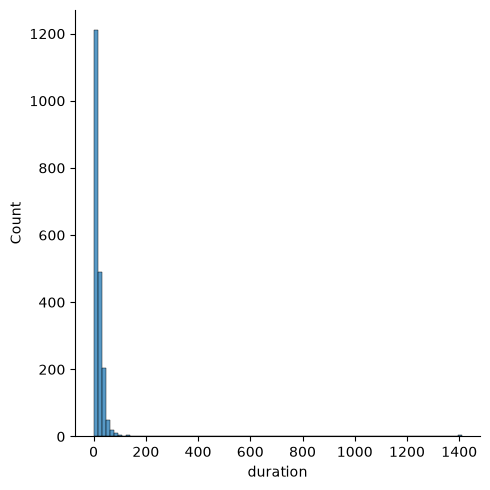

In [69]:
sns.displot(df.duration) # Plot the distribution of the trip duration

In [70]:
df.duration.describe() # Print the statistics of the trip duration

count    1999.000000
mean       19.914816
std        85.949826
min         0.000000
25%         0.116667
50%         9.683333
75%        24.550000
max      1409.083333
Name: duration, dtype: float64

In [71]:
df.duration.describe(percentiles=[0.95, 0.98, 0.99]) # Show the p95, p98, and p99 durations

count    1999.000000
mean       19.914816
std        85.949826
min         0.000000
95%        46.055000
98%        64.653333
99%        82.475333
max      1409.083333
Name: duration, dtype: float64

In [ ]:
((df.duration >= 1) & (df.duration <= 60)).mean() # mean of the trip durations that are between a minute and an hr long

np.float64(0.6053026513256629)

In [73]:
df = df[(df.duration >= 1) & (df.duration <= 60)] # Filter trips that lasted between a minute and an hour

In [74]:
df

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,...,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee,request_source,duration
11,2,2026-07-01 00:22:18,2026-07-01 00:25:18,N,5.0,92,92,1.0,0.00,20.0,...,0.00,NaN,1.0,21.00,2.0,2.0,0.00,0.00,NaN,3.000000
36,2,2026-07-01 03:51:27,2026-07-01 04:35:08,N,5.0,226,132,1.0,14.70,45.0,...,0.00,NaN,1.0,46.00,2.0,2.0,0.00,0.00,NaN,43.683333
86,2,2026-07-01 07:18:06,2026-07-01 07:23:25,N,5.0,42,41,1.0,1.34,12.0,...,0.00,NaN,1.0,13.00,2.0,2.0,0.00,0.00,NaN,5.316667
285,2,2026-07-01 10:37:00,2026-07-01 11:01:33,N,5.0,243,262,1.0,9.14,20.0,...,0.00,NaN,1.0,23.75,2.0,2.0,2.75,0.00,NaN,24.550000
309,2,2026-07-01 10:51:43,2026-07-01 11:21:09,N,5.0,65,230,1.0,7.28,50.0,...,0.00,NaN,1.0,54.50,2.0,2.0,2.75,0.75,NaN,29.433333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34767,2,2026-07-31 22:41:03,2026-07-31 23:02:34,N,5.0,93,7,1.0,5.40,45.0,...,0.00,NaN,1.0,55.20,1.0,2.0,0.00,0.00,NaN,21.516667
34800,2,2026-07-31 23:30:15,2026-08-01 00:23:24,N,5.0,97,137,2.0,7.44,50.0,...,0.00,NaN,1.0,53.75,1.0,2.0,2.75,0.00,NaN,53.150000
34802,1,2026-07-31 23:42:37,2026-07-31 23:49:01,N,5.0,28,95,0.0,1.70,25.0,...,0.00,NaN,0.0,30.00,1.0,2.0,0.00,0.00,NaN,6.400000
34808,2,2026-07-31 23:47:23,2026-08-01 00:13:32,N,5.0,112,164,1.0,4.81,65.0,...,7.46,NaN,1.0,92.35,1.0,2.0,2.75,0.75,NaN,26.150000


In [75]:
categorical = ['PULocationID', 'DOLocationID'] # Pick categorical and numerical feature columns from the data
numerical =  ['trip_distance']

In [76]:
df[categorical]

,PULocationID,DOLocationID
11,92,92
36,226,132
86,42,41
285,243,262
309,65,230
...,...,...
34767,93,7
34800,97,137
34802,28,95
34808,112,164


In [77]:
df[categorical] = df[categorical].astype(str)  # Cast the categorical values to string types

In [78]:
df

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,...,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee,request_source,duration
11,2,2026-07-01 00:22:18,2026-07-01 00:25:18,N,5.0,92,92,1.0,0.00,20.0,...,0.00,NaN,1.0,21.00,2.0,2.0,0.00,0.00,NaN,3.000000
36,2,2026-07-01 03:51:27,2026-07-01 04:35:08,N,5.0,226,132,1.0,14.70,45.0,...,0.00,NaN,1.0,46.00,2.0,2.0,0.00,0.00,NaN,43.683333
86,2,2026-07-01 07:18:06,2026-07-01 07:23:25,N,5.0,42,41,1.0,1.34,12.0,...,0.00,NaN,1.0,13.00,2.0,2.0,0.00,0.00,NaN,5.316667
285,2,2026-07-01 10:37:00,2026-07-01 11:01:33,N,5.0,243,262,1.0,9.14,20.0,...,0.00,NaN,1.0,23.75,2.0,2.0,2.75,0.00,NaN,24.550000
309,2,2026-07-01 10:51:43,2026-07-01 11:21:09,N,5.0,65,230,1.0,7.28,50.0,...,0.00,NaN,1.0,54.50,2.0,2.0,2.75,0.75,NaN,29.433333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34767,2,2026-07-31 22:41:03,2026-07-31 23:02:34,N,5.0,93,7,1.0,5.40,45.0,...,0.00,NaN,1.0,55.20,1.0,2.0,0.00,0.00,NaN,21.516667
34800,2,2026-07-31 23:30:15,2026-08-01 00:23:24,N,5.0,97,137,2.0,7.44,50.0,...,0.00,NaN,1.0,53.75,1.0,2.0,2.75,0.00,NaN,53.150000
34802,1,2026-07-31 23:42:37,2026-07-31 23:49:01,N,5.0,28,95,0.0,1.70,25.0,...,0.00,NaN,0.0,30.00,1.0,2.0,0.00,0.00,NaN,6.400000
34808,2,2026-07-31 23:47:23,2026-08-01 00:13:32,N,5.0,112,164,1.0,4.81,65.0,...,7.46,NaN,1.0,92.35,1.0,2.0,2.75,0.75,NaN,26.150000


In [79]:
df[categorical].dtypes

PULocationID    str
DOLocationID    str
dtype: object

In [80]:
train_dicts = df[categorical + numerical].to_dict(orient='records') # Transform the combined categorical and numerical dataframe to a dictionary

In [ ]:
dv = DictVectorizer() # Create a dictionary vectorizer object
X_train = dv.fit_transform(train_dicts) # Transform the dictionary into a feature vector

In [82]:
X_train

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 3630 stored elements and shape (1210, 249)>

In [83]:
dv.feature_names_  # Features used by the dict vectorizer

['DOLocationID=1',
 'DOLocationID=10',
 'DOLocationID=100',
 'DOLocationID=101',
 'DOLocationID=102',
 'DOLocationID=106',
 'DOLocationID=107',
 'DOLocationID=112',
 'DOLocationID=113',
 'DOLocationID=114',
 'DOLocationID=116',
 'DOLocationID=119',
 'DOLocationID=120',
 'DOLocationID=121',
 'DOLocationID=122',
 'DOLocationID=125',
 'DOLocationID=127',
 'DOLocationID=129',
 'DOLocationID=13',
 'DOLocationID=130',
 'DOLocationID=131',
 'DOLocationID=132',
 'DOLocationID=133',
 'DOLocationID=134',
 'DOLocationID=135',
 'DOLocationID=136',
 'DOLocationID=137',
 'DOLocationID=138',
 'DOLocationID=139',
 'DOLocationID=140',
 'DOLocationID=141',
 'DOLocationID=142',
 'DOLocationID=143',
 'DOLocationID=144',
 'DOLocationID=145',
 'DOLocationID=146',
 'DOLocationID=148',
 'DOLocationID=15',
 'DOLocationID=151',
 'DOLocationID=152',
 'DOLocationID=153',
 'DOLocationID=157',
 'DOLocationID=158',
 'DOLocationID=16',
 'DOLocationID=160',
 'DOLocationID=161',
 'DOLocationID=162',
 'DOLocationID=163'

In [84]:
target = 'duration'
y_train = df[target].values # Target vector

In [85]:
y_train

array([ 3.        , 43.68333333,  5.31666667, ...,  6.4       ,
       26.15      , 18.85      ], shape=(1210,))

In [86]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](249,)","[ 0.19,-1.78, 6.66,..., 3.56,-0.37, 1.84]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.516
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,249


In [87]:
y_pred = model.predict(X_train)  # Predict the target using the linear regression model

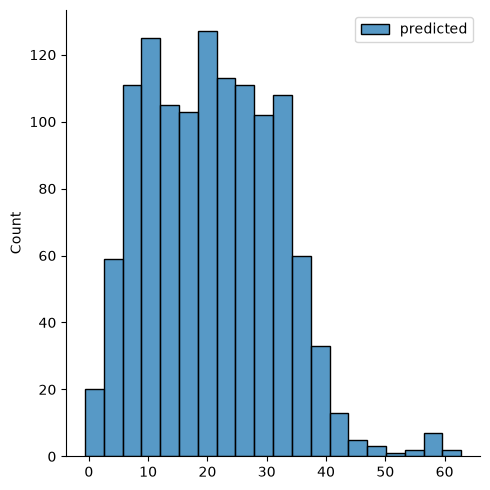

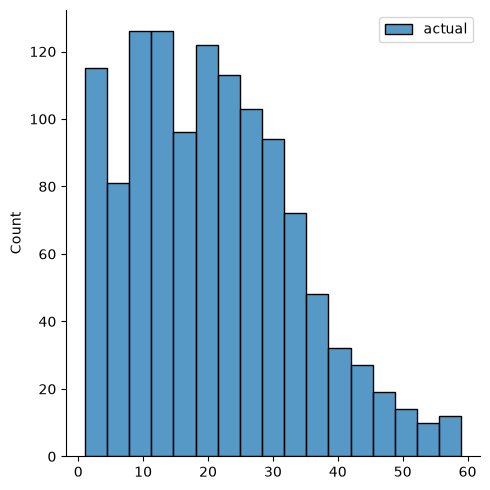

In [88]:
# Plot the distributions of the predicted and actual trip durations
sns.displot(y_pred, label='predicted')
plt.legend()
sns.displot(y_train, label='actual')
plt.legend()


In [89]:
rmse = root_mean_squared_error(y_train, y_pred) # Evaluate the performance of the model using the root mean squared error metric

In [90]:
rmse

6.445697890924662